# Exploring Retailrocket

Looking only, nothing is built here. The goal is to choose the time split,
the filter thresholds and the event weights from evidence.

## 1. Load the file

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/raw/events.csv")
df.head()

Matplotlib is building the font cache; this may take a moment.


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


## 2. Overall size and event types

In [2]:
print("events:  ", len(df))
print("visitors:", df["visitorid"].nunique())
print("items:   ", df["itemid"].nunique())
df["event"].value_counts()

events:   2756101
visitors: 1407580
items:    235061


event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64

## 3. Timeline: how is activity spread over time?

Decides where to cut train / validation / test.

from 2015-05-03 03:00:04.384000+00:00 to 2015-09-18 02:59:47.788000+00:00


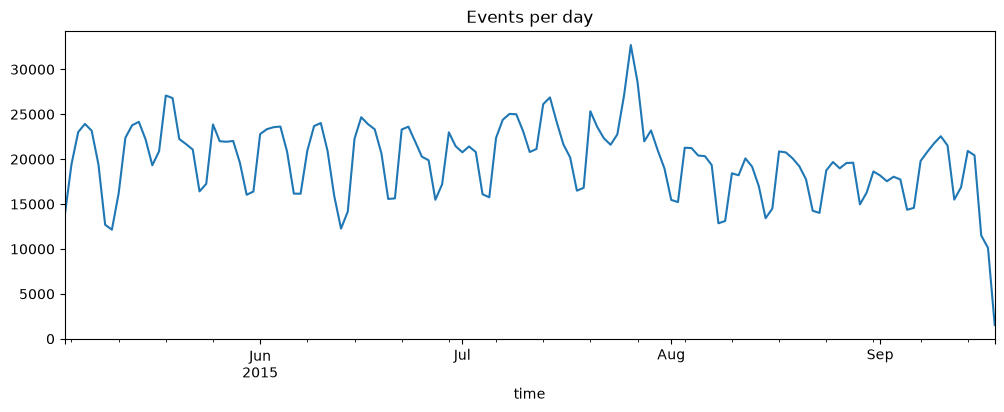

In [3]:
# timestamps are milliseconds since 1970, convert to real dates
df["time"] = pd.to_datetime(df["timestamp"], unit="ms", utc=True)
print("from", df["time"].min(), "to", df["time"].max())

per_day = df.set_index("time").resample("D").size()
per_day.plot(figsize=(12, 4), title="Events per day")
plt.show()

## 4. How active are users?

Decides the minimum interactions per user. Counted over the whole file here; the real
filter counts over the training period only.

In [4]:
per_user = df.groupby("visitorid").size()
print(per_user.describe())
for n in [1, 2, 3, 5, 10]:
    print(f"users with >= {n} events: {(per_user >= n).sum():>9}")

count    1.407580e+06
mean     1.958042e+00
std      1.258049e+01
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      2.000000e+00
max      7.757000e+03
dtype: float64
users with >= 1 events:   1407580
users with >= 2 events:    406020
users with >= 3 events:    200028
users with >= 5 events:     81620
users with >= 10 events:     23241


## 5. How popular are items?

Decides the minimum interactions per item.

In [5]:
per_item = df.groupby("itemid").size()
print(per_item.describe())
for n in [1, 2, 5, 10, 20]:
    print(f"items with >= {n} events: {(per_item >= n).sum():>9}")

count    235061.000000
mean         11.725046
std          37.032101
min           1.000000
25%           1.000000
50%           3.000000
75%           9.000000
max        3412.000000
dtype: float64
items with >= 1 events:    235061
items with >= 2 events:    161452
items with >= 5 events:     90948
items with >= 10 events:     55128
items with >= 20 events:     30547


## 6. From views to purchases

How rare each step is. Guides the event weights.

In [6]:
viewed  = df[df["event"] == "view"]["visitorid"].nunique()
carted  = df[df["event"] == "addtocart"]["visitorid"].nunique()
bought  = df[df["event"] == "transaction"]["visitorid"].nunique()
print(f"viewed something:  {viewed}")
print(f"added to cart:     {carted}  ({carted / viewed:.1%} of viewers)")
print(f"bought something:  {bought}  ({bought / viewed:.1%} of viewers)")

viewed something:  1404179
added to cart:     37722  (2.7% of viewers)
bought something:  11719  (0.8% of viewers)


## 7. Duplicates

Rows identical on time, visitor, event and item.

In [7]:
dups = df.duplicated(subset=["timestamp", "visitorid", "event", "itemid"]).sum()
print("exact duplicate rows:", dups)

exact duplicate rows: 460


## Findings

- **Timeline:** 2015-05-03 → 2015-09-18, 139 days, no gaps. Steady at ~140k events and
  ~1,100 purchases per week. The first and last days are partial (the file starts and ends
  at 03:00 UTC).
- **Users:** median 1 event; 71% have exactly one. Only 81,620 (5.8%) have 5 or more.
- **Buyers are much more active:** median 6 events, and 65% of buyers have 5 or more.
- **Extreme users:** the top visitor has 7,757 events and 559 purchases, which is a bot or
  a business account, not a shopper. Needs a decision.
- **Items:** median 3 events; 90,948 items have 5 or more.
- **Funnel:** 2.7% of viewers add to cart, 0.8% buy.
- **Duplicates:** 460 rows. Drop.

Proposed split: train before 2015-08-21, validation 2015-08-21 → 09-04, test 2015-09-04 → 09-18.